# 01 · Wstępne przetwarzanie danych eye-trackingowych

**Kurs:** Praktyczna Analiza Danych Eye-Tracking i EEG w Pythonie

W tym notebooku przejdziemy całą drogę od **surowych próbek** zarejestrowanych przez eye-tracker do **listy fiksacji i sakad**:

1. wczytanie i kontrola jakości surowych danych (czas, X, Y, średnica źrenicy),
2. wykrycie mrugnięć i interpolacja brakujących danych,
3. wygładzanie sygnału,
4. obliczenie prędkości kątowej ruchu oka,
5. detekcja fiksacji i sakad algorytmem **I-VT** (*Velocity-Threshold Identification*),
6. walidacja wyników (główna sekwencja sakad, wpływ progu, porównanie z „prawdą”).

**Dane:** 10-sekundowe nagranie (500 Hz) osoby oglądającej plakat reklamowy. Dane są symulowane, ale mają wszystkie typowe „problemy” prawdziwych nagrań: szum pomiarowy, mrugnięcia z artefaktami na brzegach i krótkie utraty sygnału. Dzięki symulacji znamy też **prawdziwe** położenie fiksacji i możemy sprawdzić, jak dobrze działa nasz algorytm.

**Szacowany czas:** ok. 90 minut.

> **Jak pracować z notebookiem?** Komórki uruchamiamy po kolei klawiszami **Shift+Enter**. Przy pierwszym uruchomieniu VS Code poprosi o wybór jądra (*Select Kernel*) – wybierz *Python Environments → Python 3.10*. Jeśli coś pójdzie nie tak, zrestartuj jądro (*Restart*) i uruchom wszystkie komórki od początku (*Run All*). Miejsca oznaczone ✏️ zachęcają do samodzielnych modyfikacji.

## 0. Przygotowanie środowiska

Importujemy biblioteki i ustalamy ścieżki do katalogów. Notebooki leżą w katalogu `notebooks/`, dane w `dane/`, a wyniki zapisujemy w `wyniki/` (ten katalog nie trafia do repozytorium).

In [54]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.signal import butter, filtfilt, savgol_filter

# Ścieżki: działają niezależnie od tego, czy notebook uruchomiono z katalogu notebooks/, czy z katalogu głównego
KATALOG_GLOWNY = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DANE = KATALOG_GLOWNY / "dane"
WYNIKI = KATALOG_GLOWNY / "wyniki"
WYNIKI.mkdir(exist_ok=True)

# Wspólny wygląd wykresów; kolory czytelne także dla osób z zaburzeniami widzenia barw
NIEBIESKI, POMARANCZOWY, MORSKI = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.prop_cycle": plt.cycler(color=[NIEBIESKI, POMARANCZOWY, MORSKI])})
print("Dane wczytujemy z katalogu:", DANE)

Dane wczytujemy z katalogu: /workspaces/MBFM_Lab/dane


## 1. Parametry stanowiska i kąt widzenia

Eye-tracker zapisuje położenie wzroku w **pikselach ekranu**. Do analizy ruchów oczu potrzebujemy jednak jednostek niezależnych od monitora – **stopni kąta widzenia** (°). Obiekt o rozmiarze $s$ oglądany z odległości $d$ zajmuje kąt

$$\theta = 2 \cdot \arctan\left(\frac{s}{2d}\right).$$

Dla orientacji: paznokieć kciuka na wyciągniętej ręce to ok. 1,5–2°, a dołek środkowy siatkówki (obszar najostrzejszego widzenia) obejmuje zaledwie ok. 1–2°. Parametry stanowiska zawsze zapisujemy w protokole badania.

In [55]:
# Parametry stanowiska badawczego (z protokołu badania)
EKRAN_SZER_PX, EKRAN_WYS_PX = 1920, 1080  # rozdzielczość monitora [px]
EKRAN_SZER_CM, EKRAN_WYS_CM = 53.1, 29.9  # fizyczny rozmiar ekranu 24" [cm]
ODLEGLOSC_CM = 60.0  # odległość oczu od ekranu [cm]
FS = 500  # częstotliwość próbkowania eye-trackera [Hz]


def px_na_stopnie(x_px, y_px):
    """Przelicza współrzędne ekranu [px] na kąt widzenia [°] względem środka ekranu."""
    x_cm = (np.asarray(x_px) - EKRAN_SZER_PX / 2) * EKRAN_SZER_CM / EKRAN_SZER_PX
    y_cm = (np.asarray(y_px) - EKRAN_WYS_PX / 2) * EKRAN_WYS_CM / EKRAN_WYS_PX
    return np.degrees(np.arctan2(x_cm, ODLEGLOSC_CM)), np.degrees(np.arctan2(y_cm, ODLEGLOSC_CM))


PX_NA_STOPIEN = EKRAN_SZER_PX / EKRAN_SZER_CM * ODLEGLOSC_CM * np.tan(np.radians(1))
print(f"W centrum ekranu 1° kąta widzenia ≈ {PX_NA_STOPIEN:.1f} px")
print(f"Cały ekran zajmuje {2 * np.degrees(np.arctan(EKRAN_SZER_CM / 2 / ODLEGLOSC_CM)):.1f}° w poziomie")

W centrum ekranu 1° kąta widzenia ≈ 37.9 px
Cały ekran zajmuje 47.7° w poziomie


## 2. Wczytanie surowych danych

Plik `et_surowe_uczestnik01.csv` zawiera cztery kolumny:

| kolumna | opis |
|---|---|
| `czas_ms` | znacznik czasu eye-trackera [ms] (liczony od włączenia urządzenia) |
| `x_px`, `y_px` | położenie wzroku na ekranie [px]; (0, 0) to **lewy górny** róg |
| `zrenica_mm` | średnica źrenicy [mm] |

Puste pola (`NaN`) oznaczają, że eye-tracker nie znalazł źrenicy – najczęściej z powodu mrugnięcia.

In [56]:
surowe = pd.read_csv(DANE / "et_surowe_uczestnik01.csv")
surowe.head()

,czas_ms,x_px,y_px,zrenica_mm
0,1843502,967.8,529.8,3.612
1,1843504,964.1,525.7,3.622
2,1843506,963.0,527.6,3.587
3,1843508,964.3,529.7,3.582
4,1843510,964.2,529.8,3.614


In [57]:
surowe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   czas_ms     5000 non-null   int64  
 1   x_px        4702 non-null   float64
 2   y_px        4702 non-null   float64
 3   zrenica_mm  4702 non-null   float64
dtypes: float64(3), int64(1)
memory usage: 156.4 KB


In [58]:
surowe.describe().round(2)

,czas_ms,x_px,y_px,zrenica_mm
count,5000.00,4702.00,4702.00,4702.00
mean,1848501.00,848.55,476.15,3.42
std,2887.04,411.67,253.19,0.15
min,1843502.00,171.40,152.60,1.96
25%,1846001.50,461.10,168.80,3.39
50%,1848501.00,811.30,569.90,3.45
75%,1851000.50,1162.60,652.80,3.49
max,1853500.00,1822.80,1099.60,3.62


Znaczniki czasu eye-trackera nie zaczynają się od zera, więc tworzymy wygodniejszą oś czasu w sekundach od początku nagrania. Sprawdzamy też, czy próbki są równomiernie rozłożone w czasie – to podstawowy test jakości nagrania.

In [59]:
surowe["t_s"] = (surowe["czas_ms"] - surowe["czas_ms"].iloc[0]) / 1000

odstepy_ms = np.diff(surowe["czas_ms"])
print("Odstępy między kolejnymi próbkami [ms]:", np.unique(odstepy_ms))
print(f"Częstotliwość próbkowania: {1000 / np.median(odstepy_ms):.0f} Hz")
print(f"Długość nagrania: {surowe['t_s'].iloc[-1]:.2f} s ({len(surowe)} próbek)")

braki = surowe[["x_px", "y_px", "zrenica_mm"]].isna()
print("\nLiczba brakujących próbek w kolumnach:", braki.sum().to_dict())
print(f"Odsetek utraconych danych: {100 * braki['x_px'].mean():.1f}%")

Odstępy między kolejnymi próbkami [ms]: [2]
Częstotliwość próbkowania: 500 Hz
Długość nagrania: 10.00 s (5000 próbek)

Liczba brakujących próbek w kolumnach: {'x_px': 298, 'y_px': 298, 'zrenica_mm': 298}
Odsetek utraconych danych: 6.0%


### Pierwszy rzut oka na dane

Wykres położenia wzroku w czasie ma charakterystyczny „schodkowy” kształt: płaskie odcinki to **fiksacje** (oko względnie nieruchome), a strome skoki to **sakady** (szybkie przeniesienia wzroku). Na czerwono zaznaczono brakujące dane.

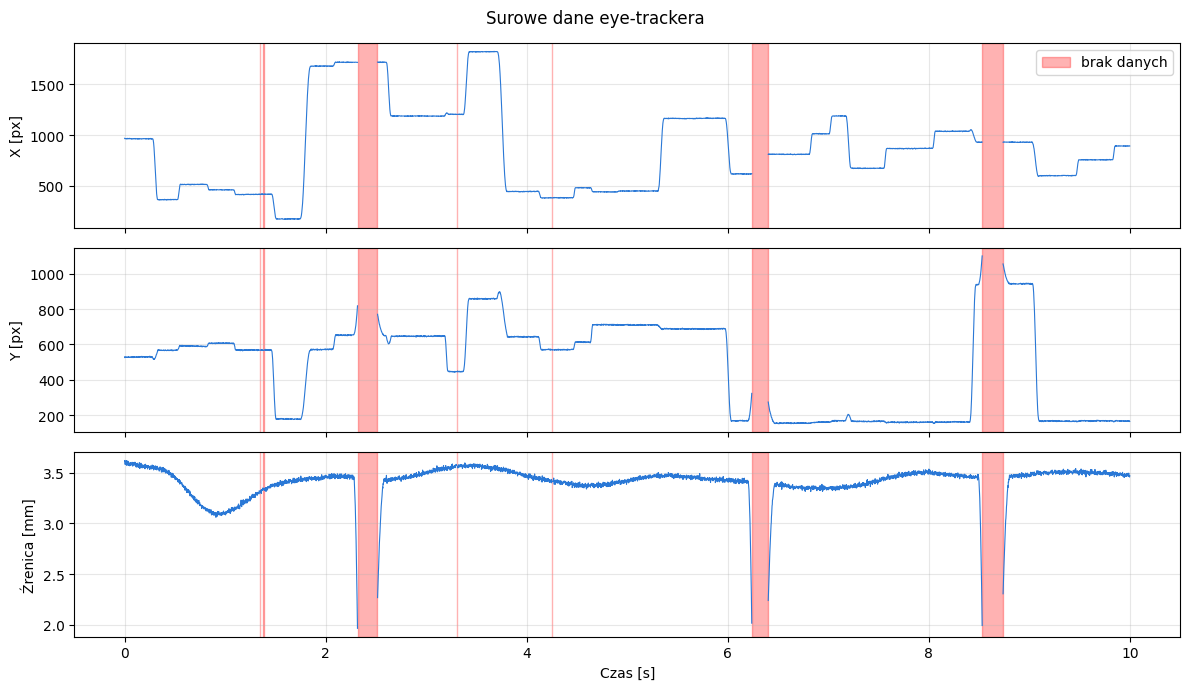

In [60]:
fig, osie = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for os_, kolumna, opis in zip(osie, ["x_px", "y_px", "zrenica_mm"], ["X [px]", "Y [px]", "Źrenica [mm]"]):
    os_.plot(surowe["t_s"], surowe[kolumna], lw=0.8)
    os_.fill_between(surowe["t_s"], 0, 1, where=braki["x_px"], color="red", alpha=0.3,
                     transform=os_.get_xaxis_transform(), label="brak danych")
    os_.set_ylabel(opis)
osie[0].legend(loc="upper right")
osie[-1].set_xlabel("Czas [s]")
fig.suptitle("Surowe dane eye-trackera")
plt.tight_layout()
plt.show()

Ten sam wykres w wersji **interaktywnej** (Plotly) – przybliż myszką okolice mrugnięć i przyjrzyj się, co dzieje się z sygnałem tuż przed i tuż po luce w danych.

In [61]:
fig = make_subplots(rows=3, cols=1, shared_xaxes=True, vertical_spacing=0.04,
                    subplot_titles=("Położenie X [px]", "Położenie Y [px]", "Średnica źrenicy [mm]"))
for wiersz, kolumna in enumerate(["x_px", "y_px", "zrenica_mm"], start=1):
    fig.add_trace(go.Scattergl(x=surowe["t_s"], y=surowe[kolumna], mode="lines", name=kolumna, line=dict(width=1)),
                  row=wiersz, col=1)
fig.update_xaxes(title_text="Czas [s]", row=3, col=1)
fig.update_layout(height=650, showlegend=False, title="Surowe dane – wersja interaktywna")
fig.show()

Zobaczmy jeszcze, gdzie na ekranie patrzyła osoba badana. Wyraźnie widać skupiska próbek (fiksacje) połączone liniami (sakady).

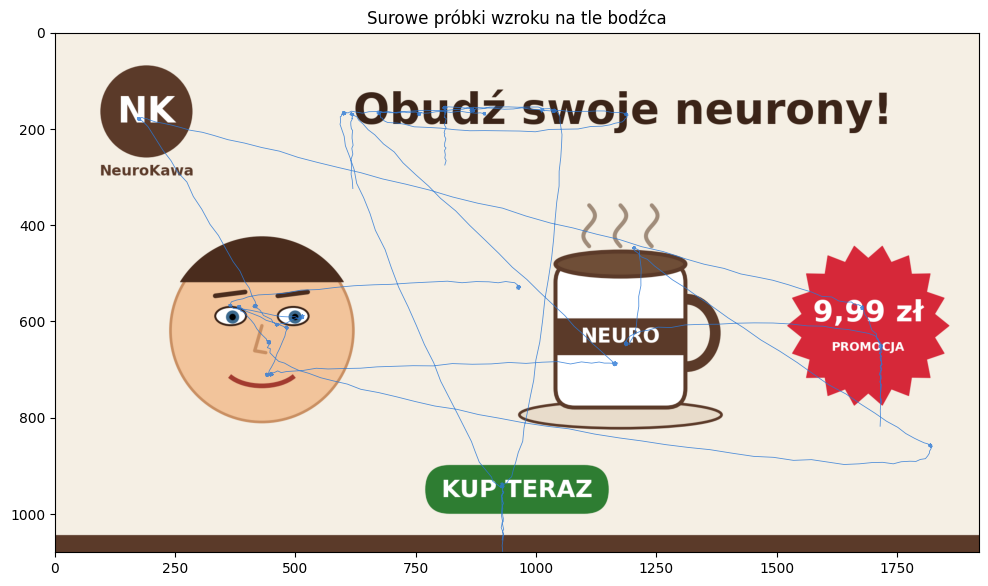

In [62]:
obraz = plt.imread(DANE / "bodziec_plakat.png")

fig, ax = plt.subplots(figsize=(12, 6.75))
ax.imshow(obraz, extent=[0, EKRAN_SZER_PX, EKRAN_WYS_PX, 0])
ax.plot(surowe["x_px"], surowe["y_px"], lw=0.6, color=NIEBIESKI, alpha=0.8)
ax.set(xlim=(0, EKRAN_SZER_PX), ylim=(EKRAN_WYS_PX, 0), title="Surowe próbki wzroku na tle bodźca")
ax.grid(False)
plt.show()

## 3. Mrugnięcia i brakujące dane

Podczas mrugnięcia powieka zasłania źrenicę, więc eye-tracker przez ok. 100–300 ms nie rejestruje danych. Problem nie ogranicza się jednak do samej luki: tuż **przed** i tuż **po** mrugnięciu powieka częściowo zasłania źrenicę, przez co:

* mierzona średnica źrenicy gwałtownie (i fałszywie) maleje,
* środek źrenicy jest źle wyznaczany – pozycja wzroku „skacze” (najczęściej w pionie).

Dlatego standardowa procedura obejmuje trzy kroki:

1. **wykrycie luk** w danych i odróżnienie mrugnięć (≥ 75 ms) od krótkich utrat sygnału,
2. **poszerzenie** okna mrugnięcia o margines przed i po luce,
3. **interpolację** usuniętych fragmentów.

Zaczynamy od funkcji pomocniczej, która znajduje ciągłe odcinki spełniające dany warunek. Przyda się nam jeszcze kilka razy.

In [63]:
def znajdz_odcinki(maska):
    """Zwraca tablicę (n, 2) z indeksami [początek, koniec) kolejnych ciągów wartości True."""
    maska = np.asarray(maska, dtype=int)
    zmiany = np.diff(np.concatenate([[0], maska, [0]]))
    return np.column_stack([np.flatnonzero(zmiany == 1), np.flatnonzero(zmiany == -1)])


# Prosty test na krótkim przykładzie
print(znajdz_odcinki([False, True, True, False, False, True]))

[[1 3]
 [5 6]]


In [64]:
MIN_CZAS_MRUGNIECIA_MS = 75  # krótsze luki traktujemy jako chwilową utratę sygnału

luki = znajdz_odcinki(surowe["x_px"].isna())
tabela_luk = pd.DataFrame({
    "start_s": surowe["t_s"].to_numpy()[luki[:, 0]],
    "czas_trwania_ms": (luki[:, 1] - luki[:, 0]) * 1000 / FS,
})
tabela_luk["rodzaj"] = np.where(tabela_luk["czas_trwania_ms"] >= MIN_CZAS_MRUGNIECIA_MS,
                                "mrugnięcie", "utrata sygnału")
tabela_luk

,start_s,czas_trwania_ms,rodzaj
0,1.342,8.0,utrata sygnału
1,1.380,8.0,utrata sygnału
2,2.318,198.0,mrugnięcie
3,3.302,8.0,utrata sygnału
4,4.250,6.0,utrata sygnału
5,6.240,162.0,mrugnięcie
6,8.532,206.0,mrugnięcie


Przyjrzyjmy się z bliska pierwszemu mrugnięciu. Zwróć uwagę na brzegi luki: spadek średnicy źrenicy i skok pozycji Y to **artefakty**, a nie prawdziwe zachowanie oka.

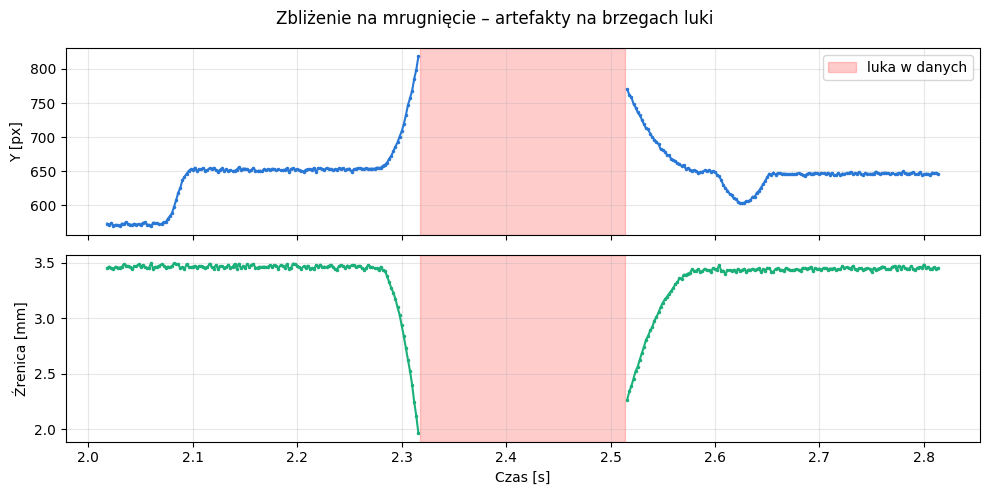

In [65]:
mrugniecia = luki[tabela_luk["rodzaj"].to_numpy() == "mrugnięcie"]
poczatek, koniec = mrugniecia[0]
okno = slice(max(poczatek - 150, 0), koniec + 150)  # ±300 ms wokół mrugnięcia

fig, osie = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
osie[0].plot(surowe["t_s"][okno], surowe["y_px"][okno], ".-", ms=3)
osie[0].set_ylabel("Y [px]")
osie[1].plot(surowe["t_s"][okno], surowe["zrenica_mm"][okno], ".-", ms=3, color=MORSKI)
osie[1].set_ylabel("Źrenica [mm]")
for os_ in osie:
    os_.axvspan(surowe["t_s"][poczatek], surowe["t_s"][koniec - 1], color="red", alpha=0.2, label="luka w danych")
osie[0].legend()
osie[1].set_xlabel("Czas [s]")
fig.suptitle("Zbliżenie na mrugnięcie – artefakty na brzegach luki")
plt.tight_layout()
plt.show()

Poszerzamy każde mrugnięcie o margines (✏️ możesz zmienić te wartości), oznaczamy te próbki jako brakujące, a następnie **interpolujemy liniowo** wszystkie luki. Zapamiętujemy przy tym maskę `brak_danych` – algorytm detekcji fiksacji nie powinien „wierzyć” danym odtworzonym przez interpolację.

In [66]:
MARGINES_PRZED_MS = 50  # ✏️
MARGINES_PO_MS = 100  # ✏️

dane = surowe.copy()
maska_mrugniec = np.zeros(len(dane), dtype=bool)
for poczatek, koniec in mrugniecia:
    p = max(poczatek - MARGINES_PRZED_MS * FS // 1000, 0)
    k = min(koniec + MARGINES_PO_MS * FS // 1000, len(dane))
    maska_mrugniec[p:k] = True

dane.loc[maska_mrugniec, ["x_px", "y_px", "zrenica_mm"]] = np.nan
dane["mrugniecie"] = maska_mrugniec
dane["brak_danych"] = dane["x_px"].isna()  # mrugnięcia (z marginesami) + krótkie utraty sygnału

for kolumna in ["x_px", "y_px", "zrenica_mm"]:
    dane[kolumna] = dane[kolumna].interpolate(method="linear", limit_direction="both")

print(f"Próbki oznaczone jako mrugnięcia: {dane['mrugniecie'].sum()} ({100 * dane['mrugniecie'].mean():.1f}%)")
print(f"Wszystkie próbki bez wiarygodnych danych: {dane['brak_danych'].sum()}")
print("Pozostałe braki po interpolacji:", int(dane[["x_px", "y_px", "zrenica_mm"]].isna().sum().sum()))

Próbki oznaczone jako mrugnięcia: 508 (10.2%)
Wszystkie próbki bez wiarygodnych danych: 523
Pozostałe braki po interpolacji: 0


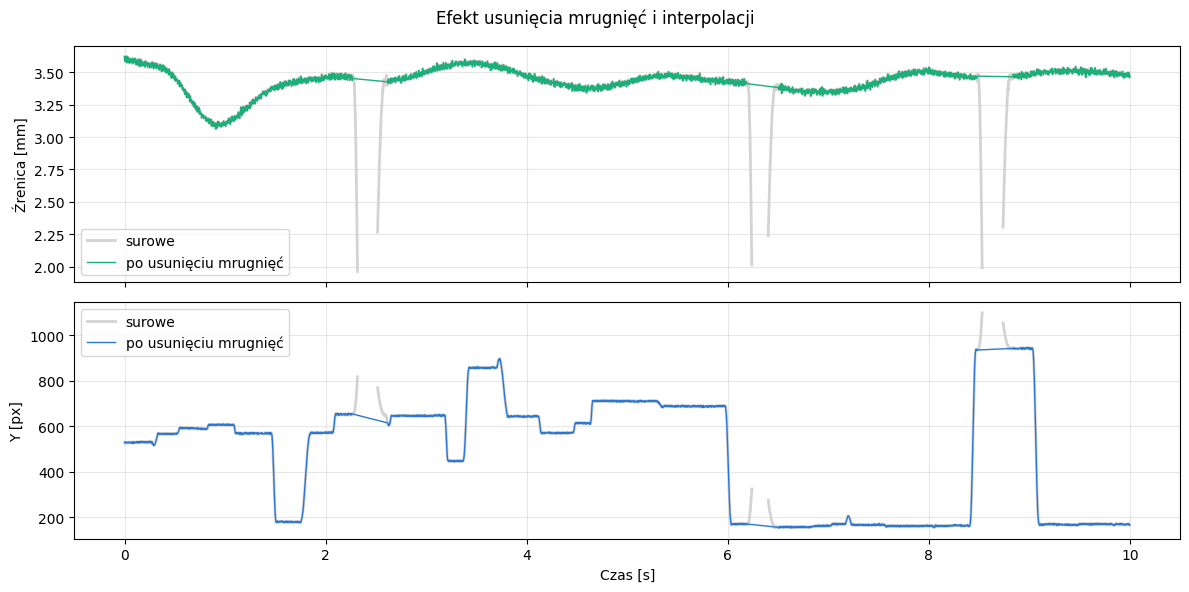

In [67]:
fig, osie = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
osie[0].plot(surowe["t_s"], surowe["zrenica_mm"], color="lightgray", lw=2, label="surowe")
osie[0].plot(dane["t_s"], dane["zrenica_mm"], color=MORSKI, lw=1, label="po usunięciu mrugnięć")
osie[0].set_ylabel("Źrenica [mm]")
osie[0].legend()
osie[1].plot(surowe["t_s"], surowe["y_px"], color="lightgray", lw=2, label="surowe")
osie[1].plot(dane["t_s"], dane["y_px"], color=NIEBIESKI, lw=1, label="po usunięciu mrugnięć")
osie[1].set_ylabel("Y [px]")
osie[1].set_xlabel("Czas [s]")
osie[1].legend()
fig.suptitle("Efekt usunięcia mrugnięć i interpolacji")
plt.tight_layout()
plt.show()

## 4. Wygładzanie sygnału

Każdy eye-tracker ma **szum pomiarowy** – nawet gdy oko jest nieruchome, kolejne próbki różnią się o ułamki stopnia. Przy liczeniu prędkości szum ten jest silnie wzmacniany (różniczkowanie wzmacnia wysokie częstotliwości), dlatego przed detekcją sakad sygnał wygładzamy.

Dla pozycji wzroku często stosuje się **filtr Savitzky'ego–Golaya**: w przesuwającym się oknie dopasowuje on wielomian niskiego stopnia. Dobrze usuwa szum, a przy tym zachowuje kształt szybkich zmian, takich jak sakady (Nyström i Holmqvist, 2010). Średnicę źrenicy, która zmienia się powoli, wygładzamy filtrem dolnoprzepustowym (4 Hz).

In [68]:
OKNO_SG_MS = 20  # ✏️ długość okna filtru Savitzky'ego–Golaya [ms]
okno_sg = int(OKNO_SG_MS * FS / 1000) | 1  # liczba próbek musi być nieparzysta

dane["x_wygl"] = savgol_filter(dane["x_px"], window_length=okno_sg, polyorder=2)
dane["y_wygl"] = savgol_filter(dane["y_px"], window_length=okno_sg, polyorder=2)

b, a = butter(N=3, Wn=4, fs=FS, btype="low")  # filtr Butterwortha, częstotliwość odcięcia 4 Hz
dane["zrenica_wygl"] = filtfilt(b, a, dane["zrenica_mm"])  # filtfilt = filtracja bez przesunięcia fazowego

print(f"Okno filtru Savitzky'ego–Golaya: {okno_sg} próbek ({okno_sg * 1000 / FS:.0f} ms)")

Okno filtru Savitzky'ego–Golaya: 11 próbek (22 ms)


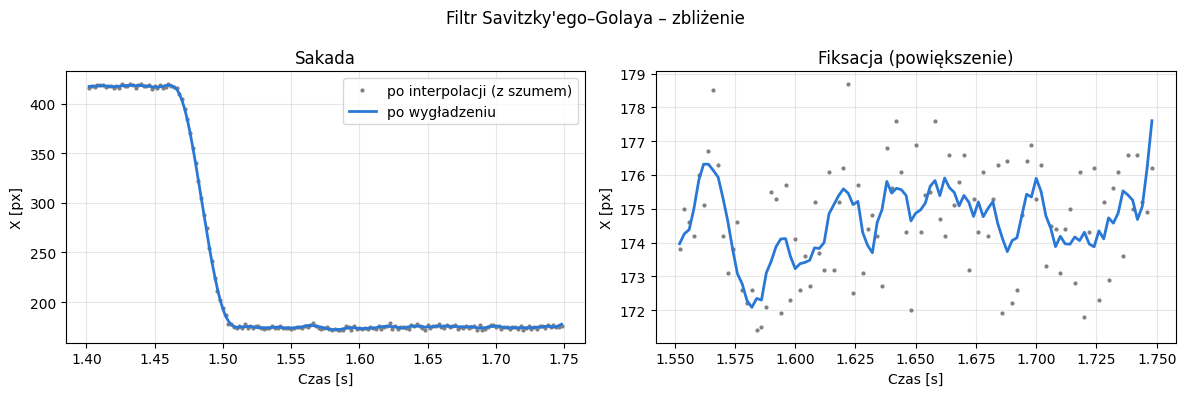

In [69]:
# Zbliżenia: sakada (lewy panel) i fragment fiksacji (prawy panel, mocno powiększona oś Y)
fig, osie = plt.subplots(1, 2, figsize=(12, 4))
for os_, (t0, t1), tytul in zip(osie, [(1.4, 1.75), (1.55, 1.75)], ["Sakada", "Fiksacja (powiększenie)"]):
    fragment = (dane["t_s"] > t0) & (dane["t_s"] < t1)
    os_.plot(dane.loc[fragment, "t_s"], dane.loc[fragment, "x_px"], ".", ms=4, color="gray",
             label="po interpolacji (z szumem)")
    os_.plot(dane.loc[fragment, "t_s"], dane.loc[fragment, "x_wygl"], color=NIEBIESKI, lw=2, label="po wygładzeniu")
    os_.set(xlabel="Czas [s]", ylabel="X [px]", title=tytul)
osie[0].legend()
fig.suptitle("Filtr Savitzky'ego–Golaya – zbliżenie")
plt.tight_layout()
plt.show()

### Średnica źrenicy po oczyszczeniu

Po usunięciu mrugnięć i wygładzeniu widać wyraźnie **odruch źreniczny na światło**: plakat jest jaśniejszy niż szary ekran wyświetlany przed nim, więc źrenica zwęża się z opóźnieniem ok. 0,3 s, a największe zwężenie następuje po ok. 1 s. W badaniach pupilometrycznych zmiany średnicy zwykle odnosimy do **linii bazowej** (np. średniej z pierwszych 200 ms).

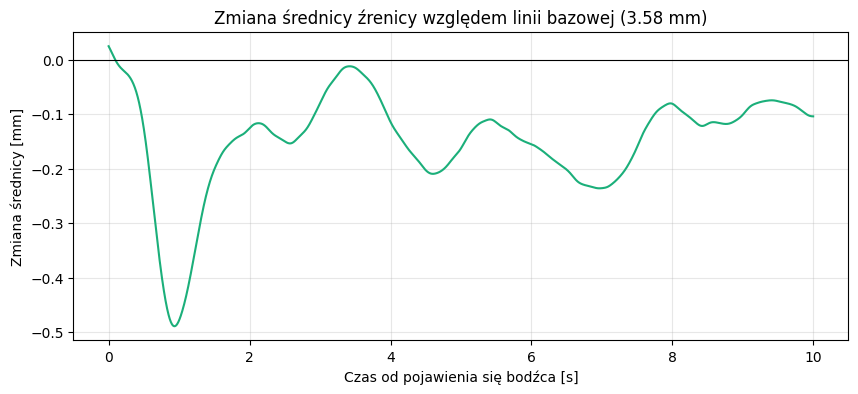

In [70]:
linia_bazowa = dane.loc[dane["t_s"] < 0.2, "zrenica_wygl"].mean()
dane["zrenica_wzgledna"] = dane["zrenica_wygl"] - linia_bazowa

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(dane["t_s"], dane["zrenica_wzgledna"], color=MORSKI)
ax.axhline(0, color="black", lw=0.8)
ax.set(xlabel="Czas od pojawienia się bodźca [s]", ylabel="Zmiana średnicy [mm]",
       title=f"Zmiana średnicy źrenicy względem linii bazowej ({linia_bazowa:.2f} mm)")
plt.show()

## 5. Prędkość kątowa ruchu oka

Algorytm I-VT klasyfikuje każdą próbkę na podstawie **prędkości kątowej** [°/s]. Przeliczamy pozycję na stopnie kąta widzenia, a następnie liczymy pochodną (różnice centralne, `np.gradient`) i długość wektora prędkości:

$$v = \sqrt{\left(\frac{dx}{dt}\right)^2 + \left(\frac{dy}{dt}\right)^2}$$

Porównamy prędkość policzoną z sygnału **niewygładzonego** i **wygładzonego**.

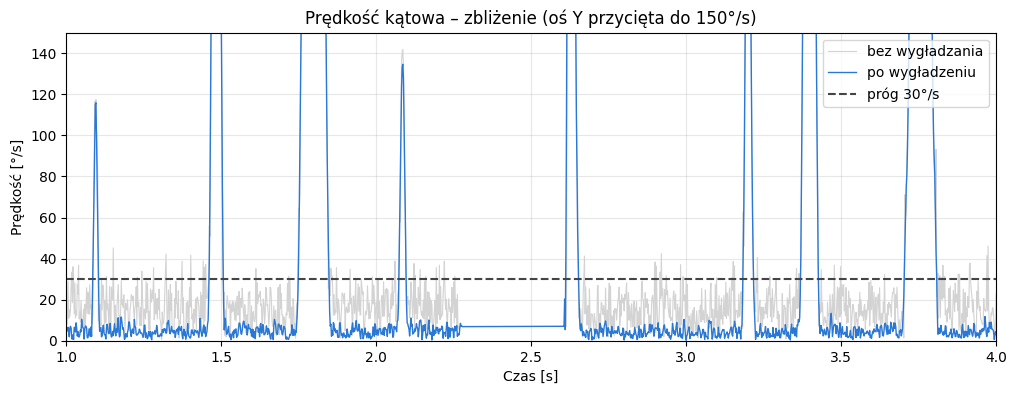

Mediana prędkości (bez wygładzania):  15.9°/s, próbki powyżej progu: 15.5%
Mediana prędkości (po wygładzeniu):   4.9°/s, próbki powyżej progu: 10.8%


In [71]:
dane["x_deg"], dane["y_deg"] = px_na_stopnie(dane["x_wygl"], dane["y_wygl"])
dane["predkosc"] = np.hypot(np.gradient(dane["x_deg"]), np.gradient(dane["y_deg"])) * FS

# Dla porównania: prędkość z danych niewygładzonych (tylko po interpolacji)
x_surowe_deg, y_surowe_deg = px_na_stopnie(dane["x_px"], dane["y_px"])
predkosc_bez_wygladzania = np.hypot(np.gradient(x_surowe_deg), np.gradient(y_surowe_deg)) * FS

PROG_PREDKOSCI = 30  # ✏️ próg I-VT [°/s] – typowa wartość (np. filtr I-VT firmy Tobii)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(dane["t_s"], predkosc_bez_wygladzania, color="lightgray", lw=0.8, label="bez wygładzania")
ax.plot(dane["t_s"], dane["predkosc"], color=NIEBIESKI, lw=1, label="po wygładzeniu")
ax.axhline(PROG_PREDKOSCI, color="#444444", ls="--", label=f"próg {PROG_PREDKOSCI}°/s")
ax.set(xlim=(1, 4), ylim=(0, 150), xlabel="Czas [s]", ylabel="Prędkość [°/s]",
       title="Prędkość kątowa – zbliżenie (oś Y przycięta do 150°/s)")
ax.legend(loc="upper right")
plt.show()

for nazwa, v in [("bez wygładzania", predkosc_bez_wygladzania), ("po wygładzeniu", dane["predkosc"])]:
    print(f"Mediana prędkości ({nazwa}): {np.median(v):5.1f}°/s, "
          f"próbki powyżej progu: {100 * np.mean(v > PROG_PREDKOSCI):4.1f}%")

Bez wygładzania szum co chwilę przekracza próg 30°/s – algorytm „widziałby” sakady w środku fiksacji. Po wygładzeniu prędkość podczas fiksacji spada do kilku °/s, a próg przekraczają niemal wyłącznie prawdziwe sakady.

## 6. Detekcja fiksacji i sakad algorytmem I-VT

Algorytm **I-VT** (Salvucci i Goldberg, 2000) to jeden z najprostszych i najczęściej stosowanych sposobów detekcji fiksacji:

1. próbki o prędkości **poniżej progu** to kandydaci na fiksacje, **powyżej progu** – sakady,
2. kolejne próbki „fiksacyjne” łączymy w fiksacje,
3. sąsiednie fiksacje oddzielone bardzo krótką przerwą (< 75 ms) i leżące blisko siebie (< 0,5°) scalamy – przerwa to zwykle chwilowy wzrost szumu,
4. odrzucamy zbyt krótkie fiksacje (< 60 ms).

Kroki 3–4 pochodzą z opisu filtru I-VT firmy Tobii (Olsen, 2012). Próbek odtworzonych przez interpolację (`brak_danych`) nie zaliczamy ani do fiksacji, ani do sakad, a fiksacji rozdzielonych mrugnięciem nie scalamy.

In [72]:
MAKS_PRZERWA_MS = 75  # łączymy fiksacje rozdzielone krótszą przerwą...
MAKS_ODLEGLOSC_DEG = 0.5  # ...jeśli ich środki leżą bliżej niż 0,5°
MIN_CZAS_FIKSACJI_MS = 60  # krótsze fiksacje odrzucamy


def wykryj_fiksacje_ivt(dane, prog=PROG_PREDKOSCI, maks_przerwa_ms=MAKS_PRZERWA_MS,
                        maks_odl_deg=MAKS_ODLEGLOSC_DEG, min_czas_ms=MIN_CZAS_FIKSACJI_MS,
                        kolumna_predkosci="predkosc"):
    """Wykrywa fiksacje algorytmem I-VT i zwraca je w postaci tabeli."""
    t = dane["t_s"].to_numpy()
    x_deg, y_deg = dane["x_deg"].to_numpy(), dane["y_deg"].to_numpy()
    brak = dane["brak_danych"].to_numpy()
    mrugniecie = dane["mrugniecie"].to_numpy()

    # Krok 1–2: ciągłe odcinki próbek o prędkości poniżej progu
    odcinki = znajdz_odcinki((dane[kolumna_predkosci].to_numpy() < prog) & ~brak)
    if len(odcinki) == 0:
        return pd.DataFrame()

    # Krok 3: scalanie sąsiednich, bliskich sobie fiksacji (ale nigdy ponad mrugnięciem)
    scalone = [list(odcinki[0])]
    for p, k in odcinki[1:]:
        pp, pk = scalone[-1]
        przerwa_ms = (t[p] - t[pk - 1]) * 1000
        odleglosc = np.hypot(x_deg[p:k].mean() - x_deg[pp:pk].mean(), y_deg[p:k].mean() - y_deg[pp:pk].mean())
        if przerwa_ms < maks_przerwa_ms and odleglosc < maks_odl_deg and not mrugniecie[pk:p].any():
            scalone[-1][1] = k
        else:
            scalone.append([p, k])

    # Krok 4: tabela fiksacji bez zbyt krótkich
    wiersze = []
    for p, k in scalone:
        czas_ms = (k - p) * 1000 / FS
        if czas_ms >= min_czas_ms:
            wiersze.append({
                "start_s": t[p], "koniec_s": t[k - 1] + 1 / FS, "czas_trwania_ms": czas_ms,
                "x_px": dane["x_wygl"].iloc[p:k].mean(), "y_px": dane["y_wygl"].iloc[p:k].mean(),
            })
    return pd.DataFrame(wiersze)


def wykryj_sakady(dane, prog=PROG_PREDKOSCI, min_czas_ms=10):
    """Zwraca tabelę sakad: ciągłe odcinki próbek o prędkości powyżej progu."""
    t, v = dane["t_s"].to_numpy(), dane["predkosc"].to_numpy()
    x_deg, y_deg = dane["x_deg"].to_numpy(), dane["y_deg"].to_numpy()
    wiersze = []
    for p, k in znajdz_odcinki((v >= prog) & ~dane["brak_danych"].to_numpy()):
        czas_ms = (k - p) * 1000 / FS
        if czas_ms < min_czas_ms:
            continue
        p0, k0 = max(p - 1, 0), min(k, len(t) - 1)  # pozycja tuż przed i tuż po przekroczeniu progu
        wiersze.append({
            "start_s": t[p], "czas_trwania_ms": czas_ms,
            "amplituda_deg": np.hypot(x_deg[k0] - x_deg[p0], y_deg[k0] - y_deg[p0]),
            "predkosc_szczytowa": v[p:k].max(),
        })
    return pd.DataFrame(wiersze)


fiksacje = wykryj_fiksacje_ivt(dane)
sakady = wykryj_sakady(dane)
print(f"Wykryto {len(fiksacje)} fiksacji i {len(sakady)} sakad")
fiksacje.head(10).round(2)

Wykryto 27 fiksacji i 25 sakad


,start_s,koniec_s,czas_trwania_ms,x_px,y_px
0,0.00,0.28,278.0,963.71,529.46
1,0.33,0.53,196.0,364.62,567.21
2,0.55,0.82,266.0,514.16,590.86
3,0.84,1.09,246.0,461.30,606.94
4,1.11,1.46,356.0,416.38,568.72
5,1.51,1.75,242.0,174.62,179.56
6,1.85,2.07,226.0,1677.97,571.67
7,2.10,2.27,170.0,1715.91,652.67
8,2.65,3.18,530.0,1186.86,646.81
9,3.22,3.37,152.0,1203.89,447.07


In [73]:
print("Fiksacje – statystyki opisowe:")
print(fiksacje["czas_trwania_ms"].describe().round(1).to_string())
print("\nSakady – statystyki opisowe:")
print(sakady[["czas_trwania_ms", "amplituda_deg", "predkosc_szczytowa"]].describe().round(1).to_string())

Fiksacje – statystyki opisowe:
count     27.0
mean     292.5
std      137.4
min      136.0
25%      181.0
50%      276.0
75%      338.0
max      648.0

Sakady – statystyki opisowe:
       czas_trwania_ms  amplituda_deg  predkosc_szczytowa
count             25.0           25.0                25.0
mean              43.0           11.0               354.3
std               23.7           10.5               185.7
min               20.0            1.4                98.2
25%               26.0            3.6               212.4
50%               30.0            5.3               272.4
75%               58.0           18.6               528.7
max              106.0           39.5               686.8


### Wizualizacja wyników detekcji

Na wykresie pozycji w czasie zaznaczamy wykryte fiksacje (zielone pasy) i mrugnięcia (szare pasy). Dobra detekcja powinna pokrywać każdy płaski fragment sygnału jedną fiksacją.

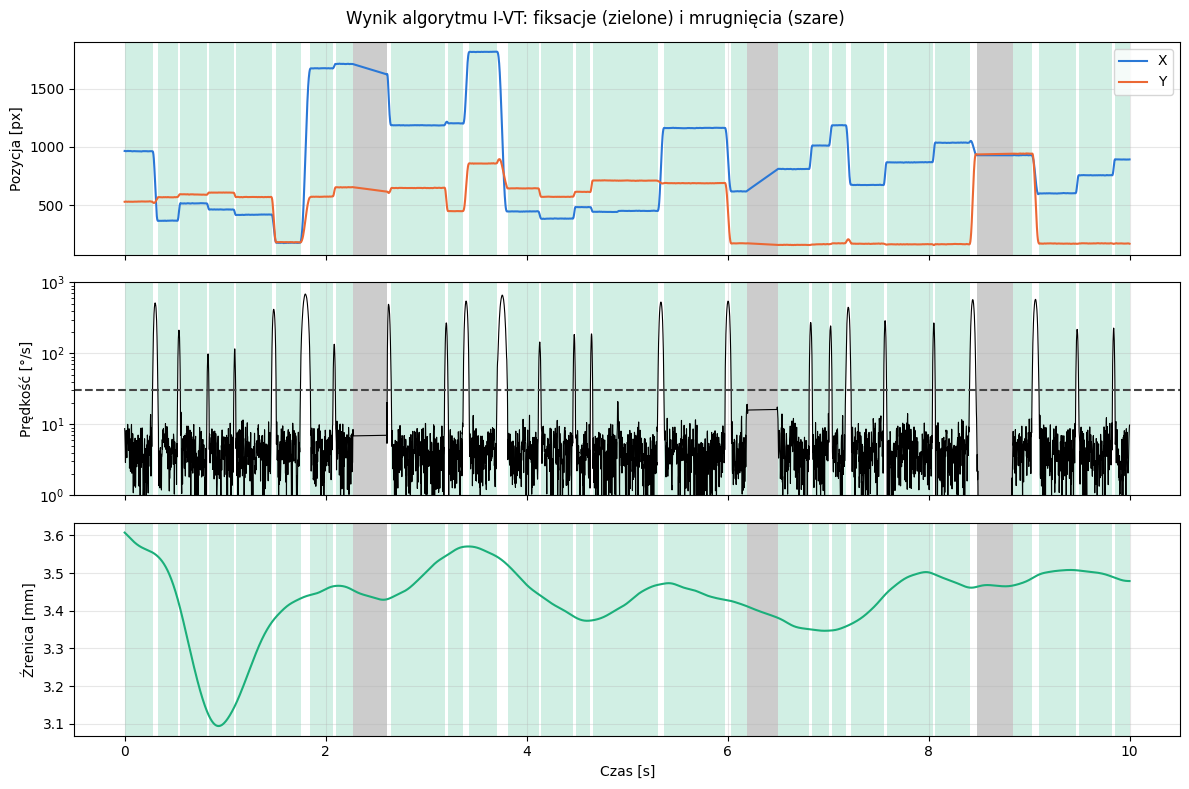

In [74]:
fig, osie = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
osie[0].plot(dane["t_s"], dane["x_wygl"], color=NIEBIESKI, label="X")
osie[0].plot(dane["t_s"], dane["y_wygl"], color=POMARANCZOWY, label="Y")
osie[0].set_ylabel("Pozycja [px]")
osie[0].legend(loc="upper right")
osie[1].plot(dane["t_s"], dane["predkosc"], color="black", lw=0.8)
osie[1].axhline(PROG_PREDKOSCI, color="#444444", ls="--")
osie[1].set(ylabel="Prędkość [°/s]", yscale="log", ylim=(1, 1000))
osie[2].plot(dane["t_s"], dane["zrenica_wygl"], color=MORSKI)
osie[2].set(ylabel="Źrenica [mm]", xlabel="Czas [s]")
for os_ in osie:
    for _, f in fiksacje.iterrows():
        os_.axvspan(f["start_s"], f["koniec_s"], color=MORSKI, alpha=0.2, lw=0)
    for p, k in znajdz_odcinki(dane["mrugniecie"]):
        os_.axvspan(dane["t_s"].iloc[p], dane["t_s"].iloc[k - 1], color="gray", alpha=0.4, lw=0)
fig.suptitle("Wynik algorytmu I-VT: fiksacje (zielone) i mrugnięcia (szare)")
plt.tight_layout()
plt.show()

A tak wyglądają wykryte fiksacje na tle bodźca. Wielkość koła odpowiada czasowi trwania fiksacji – to zapowiedź wizualizacji, którymi zajmiemy się w notebooku 02.

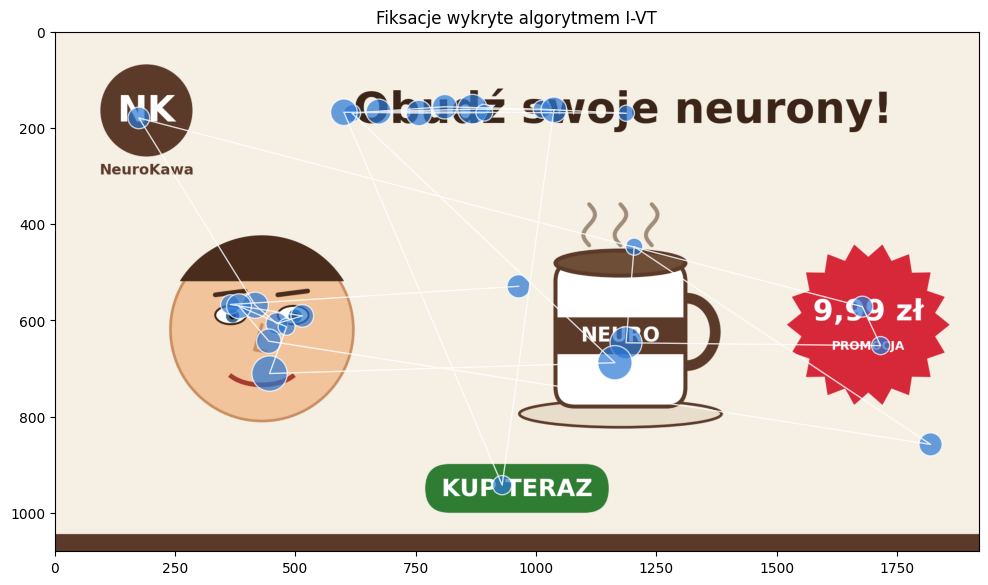

In [75]:
fig, ax = plt.subplots(figsize=(12, 6.75))
ax.imshow(obraz, extent=[0, EKRAN_SZER_PX, EKRAN_WYS_PX, 0])
ax.plot(fiksacje["x_px"], fiksacje["y_px"], color="white", lw=1, alpha=0.8)
ax.scatter(fiksacje["x_px"], fiksacje["y_px"], s=fiksacje["czas_trwania_ms"], color=NIEBIESKI,
           alpha=0.7, edgecolor="white")
ax.set(xlim=(0, EKRAN_SZER_PX), ylim=(EKRAN_WYS_PX, 0), title="Fiksacje wykryte algorytmem I-VT")
ax.grid(False)
plt.show()

## 7. Walidacja wyników

### 7.1. Główna sekwencja sakad

Sakady mają stałą „sygnaturę”: im większa amplituda, tym większa prędkość szczytowa (zależność potęgowa, która nasyca się przy ok. 500–700°/s). To tzw. **główna sekwencja** (*main sequence*; Bahill i in., 1975). Jeśli wykryte „sakady” leżą daleko od tej zależności, prawdopodobnie są artefaktami (np. pozostałościami po mrugnięciach).

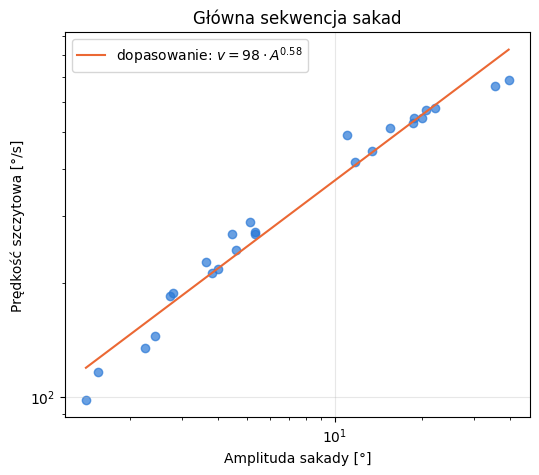

In [76]:
wsp_b, wsp_a = np.polyfit(np.log10(sakady["amplituda_deg"]), np.log10(sakady["predkosc_szczytowa"]), 1)
amplitudy = np.logspace(np.log10(sakady["amplituda_deg"].min()), np.log10(sakady["amplituda_deg"].max()), 50)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(sakady["amplituda_deg"], sakady["predkosc_szczytowa"], alpha=0.7)
ax.plot(amplitudy, 10**wsp_a * amplitudy**wsp_b, color=POMARANCZOWY,
        label=f"dopasowanie: $v = {10**wsp_a:.0f} \\cdot A^{{{wsp_b:.2f}}}$")
ax.set(xscale="log", yscale="log", xlabel="Amplituda sakady [°]", ylabel="Prędkość szczytowa [°/s]",
       title="Główna sekwencja sakad")
ax.legend()
plt.show()

### 7.2. Jak wynik zależy od progu prędkości?

Próg I-VT jest parametrem wybieranym przez badacza, więc warto sprawdzić, jak bardzo wyniki od niego zależą. Powtarzamy detekcję dla różnych progów w trzech wariantach: pełny algorytm (wygładzanie + scalanie fiksacji) oraz dwa warianty uproszczone, bez kroku scalania – na danych wygładzonych i niewygładzonych.

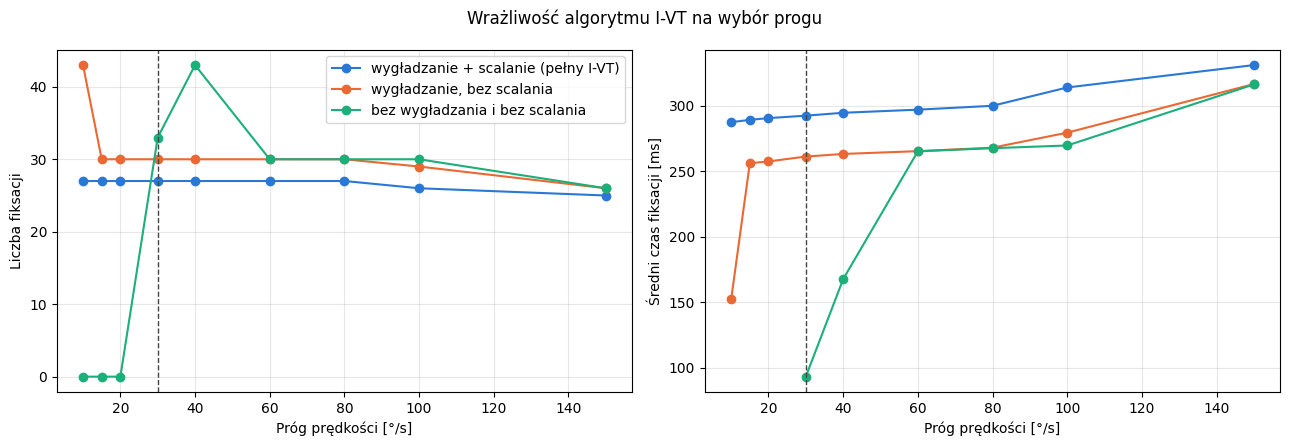

wariant,bez wygładzania i bez scalania,wygładzanie + scalanie (pełny I-VT),"wygładzanie, bez scalania"
próg [°/s],,,
10,0,27,43
15,0,27,30
20,0,27,30
30,33,27,30
40,43,27,30
60,30,27,30
80,30,27,30
100,30,26,29
150,26,25,26


In [77]:
dane["predkosc_bez_wygladzania"] = predkosc_bez_wygladzania
warianty = {
    "wygładzanie + scalanie (pełny I-VT)": dict(kolumna_predkosci="predkosc"),
    "wygładzanie, bez scalania": dict(kolumna_predkosci="predkosc", maks_przerwa_ms=0),
    "bez wygładzania i bez scalania": dict(kolumna_predkosci="predkosc_bez_wygladzania", maks_przerwa_ms=0),
}
wyniki_progow = []
for prog in [10, 15, 20, 30, 40, 60, 80, 100, 150]:
    for opis, parametry in warianty.items():
        f = wykryj_fiksacje_ivt(dane, prog=prog, **parametry)
        wyniki_progow.append({"próg [°/s]": prog, "wariant": opis, "liczba fiksacji": len(f),
                              "średni czas fiksacji [ms]": f["czas_trwania_ms"].mean() if len(f) else np.nan})
wyniki_progow = pd.DataFrame(wyniki_progow)

fig, osie = plt.subplots(1, 2, figsize=(13, 4.5))
for opis in warianty:
    grupa = wyniki_progow[wyniki_progow["wariant"] == opis]
    osie[0].plot(grupa["próg [°/s]"], grupa["liczba fiksacji"], "o-", label=opis)
    osie[1].plot(grupa["próg [°/s]"], grupa["średni czas fiksacji [ms]"], "o-", label=opis)
osie[0].set(xlabel="Próg prędkości [°/s]", ylabel="Liczba fiksacji")
osie[1].set(xlabel="Próg prędkości [°/s]", ylabel="Średni czas fiksacji [ms]")
for os_ in osie:
    os_.axvline(PROG_PREDKOSCI, color="#444444", ls="--", lw=1)
osie[0].legend()
fig.suptitle("Wrażliwość algorytmu I-VT na wybór progu")
plt.tight_layout()
plt.show()

wyniki_progow.pivot(index="próg [°/s]", columns="wariant", values="liczba fiksacji")

Pełny algorytm daje niemal ten sam wynik w szerokim zakresie progów – to dobra wiadomość. Bez kroku scalania wynik bardziej zależy od progu, a bez wygładzania algorytm wręcz się „sypie”: przy niskich progach szum dzieli fiksacje na kawałki krótsze niż 60 ms, które są odrzucane (w skrajnym przypadku nie zostaje ani jedna fiksacja!). **Wygładzanie i scalanie to dwa niezależne zabezpieczenia przed szumem.**

### 7.3. Porównanie z „prawdą”

Ponieważ dane są symulowane, znamy prawdziwe fiksacje tej osoby. Zapisano je w pliku z raportem fiksacji całej grupy (`et_fiksacje_grupa.csv`, uczestnik `U01`), z którego skorzystamy w notebooku 02. Porównajmy je z wynikiem naszego algorytmu.

Prawdziwe fiksacje: 28, średni czas trwania 314 ms
Wykryte fiksacje:   27, średni czas trwania 293 ms


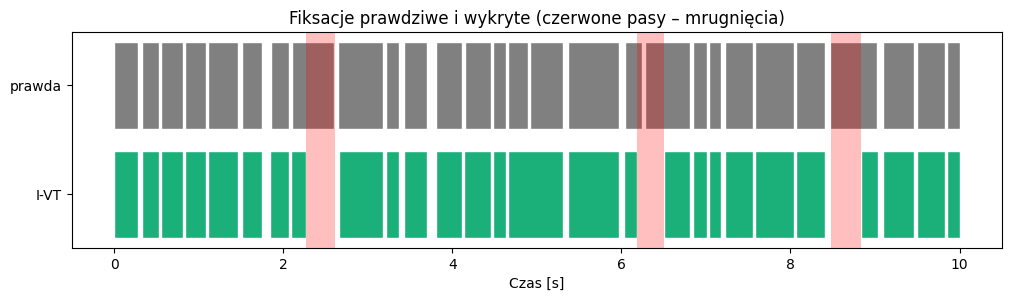

In [78]:
prawda = pd.read_csv(DANE / "et_fiksacje_grupa.csv").query("uczestnik == 'U01'")
print(f"Prawdziwe fiksacje: {len(prawda)}, średni czas trwania {prawda['czas_trwania_ms'].mean():.0f} ms")
print(f"Wykryte fiksacje:   {len(fiksacje)}, średni czas trwania {fiksacje['czas_trwania_ms'].mean():.0f} ms")

fig, ax = plt.subplots(figsize=(12, 2.8))
ax.broken_barh(list(zip(prawda["start_ms"] / 1000, prawda["czas_trwania_ms"] / 1000)), (1.1, 0.8),
               color="gray", edgecolor="white")
ax.broken_barh(list(zip(fiksacje["start_s"], fiksacje["czas_trwania_ms"] / 1000)), (0.1, 0.8),
               color=MORSKI, edgecolor="white")
for p, k in znajdz_odcinki(dane["mrugniecie"]):
    ax.axvspan(dane["t_s"].iloc[p], dane["t_s"].iloc[k - 1], color="red", alpha=0.25, lw=0)
ax.set(yticks=[0.5, 1.5], yticklabels=["I-VT", "prawda"], xlabel="Czas [s]",
       title="Fiksacje prawdziwe i wykryte (czerwone pasy – mrugnięcia)")
ax.grid(False)
plt.show()

Większość fiksacji odtworzyliśmy bardzo dokładnie. Różnice pojawiają się w dwóch sytuacjach:

* przy **mrugnięciach** – mrugnięcie w środku fiksacji dzieli ją na dwie części albo „zjada” krótką fiksację,
* przy **bardzo małych sakadach** – ich prędkość może nie przekroczyć progu, więc dwie sąsiednie fiksacje zlewają się w jedną.

To normalne ograniczenia algorytmu I-VT. W raportach z badań zawsze podajemy parametry detekcji i sposób traktowania mrugnięć.

## 8. Zapis wyników

Zapisujemy tabelę fiksacji i oczyszczone próbki do katalogu `wyniki/`.

In [79]:
fiksacje.round(3).to_csv(WYNIKI / "01_fiksacje_U01.csv", index=False)
sakady.round(3).to_csv(WYNIKI / "01_sakady_U01.csv", index=False)
dane[["t_s", "x_wygl", "y_wygl", "zrenica_wygl", "predkosc", "mrugniecie", "brak_danych"]].round(4).to_csv(
    WYNIKI / "01_probki_oczyszczone_U01.csv", index=False)
print("Zapisano pliki:", *sorted(p.name for p in WYNIKI.glob("01_*")), sep="\n  ")

Zapisano pliki:
  01_fiksacje_U01.csv
  01_probki_oczyszczone_U01.csv
  01_sakady_U01.csv


## Podsumowanie

* Surowe dane eye-trackingowe wymagają kontroli jakości: sprawdzamy częstotliwość próbkowania i odsetek utraconych danych.
* Mrugnięcia usuwamy **razem z marginesem**, bo brzegi luk zawierają artefakty (fałszywy spadek źrenicy, skoki pozycji).
* Przed liczeniem prędkości sygnał trzeba wygładzić – inaczej szum udaje sakady.
* Algorytm I-VT jest prosty i skuteczny, ale jego wyniki zależą od parametrów (próg, scalanie, minimalny czas fiksacji). Zawsze je raportujemy.
* Główna sekwencja sakad to szybki test poprawności detekcji.

## Zadania do samodzielnego wykonania

Pięć zadań, w których powtórzysz najważniejsze kroki z tego notebooka. **Nie wymagają nowych funkcji ani pojęć** – wszystko, czego potrzebujesz, pojawiło się wyżej (przy każdym zadaniu podajemy, którą sekcję powtarza). Każde zadanie kończy się **jednym wynikiem**: liczbą wypisaną w podanym formacie albo jedną figurą.

**Zasady pracy**

1. Zanim zaczniesz, uruchom cały notebook (**Run All**) – zadania korzystają ze zmiennych i funkcji zdefiniowanych wyżej.
2. Rozwiązanie wpisz w komórce kodu pod treścią zadania.
3. **Nie nadpisuj zmiennych z notebooka** (np. `dane`, `fiksacje`, `sakady`). Nowym zmiennym nadawaj nazwy z przedrostkiem zadania: `z1_`, `z2_`, … Dzięki temu zadania nie psują sobie nawzajem danych i nie trzeba uruchamiać notebooka od nowa.
4. **Kontrola pośrednia** to wartość, którą możesz sprawdzić po drodze. Jeśli się nie zgadza, błąd jest wcześniej – popraw go, zanim pójdziesz dalej.
5. **✅ Wynik** to jedyna rzecz do oddania: liczba wypisana dokładnie w podanym formacie (z podaną liczbą miejsc po przecinku) albo figura z podanym tytułem.
6. **Do przemyślenia** – pytanie, które pomaga zrozumieć wynik. Nie trzeba go oddawać, ale warto na nie odpowiedzieć choćby w myślach.

### Zadanie 1. Rozmiar obszaru w stopniach kąta widzenia

*Powtarzasz: sekcja 1 (parametry stanowiska i kąt widzenia).*

**Cel:** przećwiczyć przeliczanie pikseli na stopnie i zobaczyć, że rozmiar kątowy obiektu zależy od odległości oczu od ekranu.

AOI „Twarz” na plakacie zajmuje w poziomie piksele od 230 do 630, czyli ma 400 px szerokości.

**Krok po kroku:**

1. Zamień szerokość AOI z pikseli na centymetry. Znasz szerokość ekranu w centymetrach (`EKRAN_SZER_CM`) i w pikselach (`EKRAN_SZER_PX`) – tak samo przelicza to funkcja `px_na_stopnie`.
2. Policz rozmiar kątowy ze wzoru z sekcji 1: $\theta = 2 \cdot \arctan\left(\frac{s}{2d}\right)$. Użyj `np.arctan`, a wynik w radianach zamień na stopnie funkcją `np.degrees`. Uwaga: $s$ i $d$ muszą być w tych samych jednostkach (cm).
3. Policz $\theta$ najpierw dla $d$ = 60 cm (odległość z naszego stanowiska), a potem dla $d$ = 70 cm.

**Kontrola pośrednia:** dla 60 cm wychodzi ok. 10,5°.

**✅ Wynik:** `print(f"Zadanie 1: {z1_theta_70:.1f}°")` – szerokość AOI „Twarz” w stopniach, gdy badany siedzi 70 cm od ekranu.

**Do przemyślenia:** Czy próg prędkości I-VT (30°/s) trzeba zmieniać, gdy badany siedzi dalej od ekranu? A gdyby próg był wyrażony w pikselach na sekundę?

In [80]:
# Zadanie 1 – Twoje rozwiązanie
EKRAN_SZER_PX = 1920  # rozdzielczość monitora [px]
EKRAN_SZER_CM = 53.1  # fizyczny rozmiar ekranu 24" [cm]
ODLEGLOSC_CM = 60.0  # odległość oczu od ekranu [cm]
FS = 500  # częstotliwość próbkowania eye-trackera [Hz]

AOI_TWARZ_PX = 400
aoi_twarz_cm = (AOI_TWARZ_PX *EKRAN_SZER_CM/EKRAN_SZER_PX)

def px_na_stopnie(x_px, y_px):
    """Przelicza współrzędne ekranu [px] na kąt widzenia [°] względem środka ekranu."""
    x_cm = (np.asarray(x_px) - EKRAN_SZER_PX / 2) * EKRAN_SZER_CM / EKRAN_SZER_PX
    y_cm = (np.asarray(y_px) - EKRAN_WYS_PX / 2) * EKRAN_WYS_CM / EKRAN_WYS_PX
    return np.degrees(np.arctan2(x_cm, ODLEGLOSC_CM)), np.degrees(np.arctan2(y_cm, ODLEGLOSC_CM))

PX_NA_STOPIEN = EKRAN_SZER_PX / EKRAN_SZER_CM * ODLEGLOSC_CM * np.tan(np.radians(1))

print(f"W centrum ekranu 1° kąta widzenia ≈ {PX_NA_STOPIEN:.1f} px")
print(f"Cały ekran zajmuje {2 * np.degrees(np.arctan(EKRAN_SZER_CM / 2 / ODLEGLOSC_CM)):.1f}° w poziomie")

z1_theta_60 = np.degrees(
    2 * np.arctan(aoi_twarz_cm / (2 * 60))
)

z1_theta_70 = np.degrees(
    2 * np.arctan(aoi_twarz_cm / (2 * 70))
)

print(f"Rozmiar AOI dla 60 cm: {z1_theta_60}°")
print(f"Zadanie 1: {z1_theta_70}°")


W centrum ekranu 1° kąta widzenia ≈ 37.9 px
Cały ekran zajmuje 47.7° w poziomie
Rozmiar AOI dla 60 cm: 10.5341351050449°
Zadanie 1: 9.036004251970958°


### Zadanie 2. Po co marginesy wokół mrugnięć?

*Powtarzasz: sekcje 3–6 (cały potok od surowych próbek do sakad).*

**Cel:** złożyć wstępne przetwarzanie w jedną funkcję i sprawdzić, co się stanie, gdy usuniemy mrugnięcia **bez** marginesów.

**Krok po kroku:**

1. Napisz funkcję `przetworz(surowe, margines_przed_ms, margines_po_ms, okno_sg_ms)`, która zwraca nową tabelę gotową do detekcji. W środku powtórz po kolei kod z notebooka, zamieniając stałe (`MARGINES_PRZED_MS`, `MARGINES_PO_MS`, `OKNO_SG_MS`) na argumenty funkcji:
   * **sekcja 3** (komórka z `MARGINES_PRZED_MS`): kopia danych (`surowe.copy()`), maska mrugnięć poszerzona o marginesy (pętla po tablicy `mrugniecia`), kolumny `mrugniecie` i `brak_danych`, interpolacja liniowa kolumn `x_px`, `y_px` i `zrenica_mm`;
   * **sekcja 4**: wygładzanie `x_px` i `y_px` filtrem Savitzky'ego–Golaya → kolumny `x_wygl` i `y_wygl` (długość okna w próbkach liczysz z `okno_sg_ms` tak jak w notebooku);
   * **sekcja 5**: kolumny `x_deg`, `y_deg` (funkcja `px_na_stopnie`) i `predkosc`.

   Funkcje `wykryj_fiksacje_ivt` i `wykryj_sakady` potrzebują kolumn: `t_s` (jest już w `surowe`), `x_wygl`, `y_wygl`, `x_deg`, `y_deg`, `predkosc`, `mrugniecie` i `brak_danych`. Średnicy źrenicy nie musisz wygładzać.
2. Sprawdź funkcję na ustawieniach z notebooka: `z2_dane = przetworz(surowe, 50, 100, 20)`, a potem policz fiksacje (`wykryj_fiksacje_ivt(z2_dane)`) i sakady (`wykryj_sakady(z2_dane)`).
3. Uruchom funkcję jeszcze raz **bez marginesów** (`margines_przed_ms=0`, `margines_po_ms=0`, okno 20 ms) i policz sakady.

**Kontrola pośrednia:** dla marginesów 50 i 100 ms oraz okna 20 ms funkcja musi dać dokładnie **27 fiksacji i 25 sakad** – tak jak w notebooku.

**✅ Wynik:** `print(f"Zadanie 2: {len(z2_sakady)} sakad")` – liczba sakad wykrytych bez marginesów.

**Do przemyślenia:** Skąd wzięły się dodatkowe „sakady”? Porównaj ich czasy początku (`start_s`) z tabelą mrugnięć `tabela_luk` z sekcji 3. Gdzie leżałyby na wykresie głównej sekwencji?

In [81]:
# Zadanie 2 – Twoje rozwiązanie
def przetworz(surowe, margines_przed_ms,margines_po_ms,okno_sg_ms_):

    margines_przed_ms = 50  # ✏️
    margines_po_ms = 100  # ✏️

    dane = surowe.copy()
    maska_mrugniec = np.zeros(len(dane), dtype=bool)
    for poczatek, koniec in mrugniecia:
        p = max(poczatek - margines_przed_ms * FS // 1000, 0)
        k = min(koniec + margines_po_ms * FS // 1000, len(dane))
        maska_mrugniec[p:k] = True

    dane.loc[maska_mrugniec, ["x_px", "y_px", "zrenica_mm"]] = np.nan
    dane["mrugniecie"] = maska_mrugniec
    dane["brak_danych"] = dane["x_px"].isna()  # mrugnięcia (z marginesami) + krótkie utraty sygnału

    for kolumna in ["x_px", "y_px", "zrenica_mm"]:
        dane[kolumna] = dane[kolumna].interpolate(method="linear", limit_direction="both")

    
    okno_sg_ms_ = 20  # ✏️ długość okna filtru Savitzky'ego–Golaya [ms]
    okno_sg = int(okno_sg_ms_ * FS / 1000) | 1  # liczba próbek musi być nieparzysta

    dane["x_wygl"] = savgol_filter(dane["x_px"], window_length=okno_sg, polyorder=2)
    dane["y_wygl"] = savgol_filter(dane["y_px"], window_length=okno_sg, polyorder=2)

    b, a = butter(N=3, Wn=4, fs=FS, btype="low")  # filtr Butterwortha, częstotliwość odcięcia 4 Hz
    dane["zrenica_wygl"] = filtfilt(b, a, dane["zrenica_mm"])  # filtfilt = filtracja bez przesunięcia fazowego

    dane["x_deg"], dane["y_deg"] = px_na_stopnie(dane["x_wygl"], dane["y_wygl"])
    dane["predkosc"] = np.hypot(np.gradient(dane["x_deg"]), np.gradient(dane["y_deg"])) * FS

    # Dla porównania: prędkość z danych niewygładzonych (tylko po interpolacji)
    x_surowe_deg, y_surowe_deg = px_na_stopnie(dane["x_px"], dane["y_px"])
    predkosc_bez_wygladzania = np.hypot(np.gradient(x_surowe_deg), np.gradient(y_surowe_deg)) * FS

    PROG_PREDKOSCI = 30  # ✏️ próg I-VT [°/s] – typowa wartość (np. filtr I-VT firmy Tobii)


    
    return dane 
# print(f"Zadanie 2: {len(z2_sakady)} sakad")

In [82]:
z2_dane = przetworz(surowe,50,100,20)

z2_fiksacje = wykryj_fiksacje_ivt(z2_dane)
z2_sakady = wykryj_sakady(z2_dane)

print(z2_fiksacje)
print(z2_sakady)
print(f"Zadanie 2: {len(z2_sakady)} sakad")

    start_s  koniec_s  czas_trwania_ms         x_px        y_px
0     0.000     0.278            278.0   963.711865  529.464929
1     0.332     0.528            196.0   364.619828  567.206184
2     0.554     0.820            266.0   514.162597  590.856996
3     0.840     1.086            246.0   461.304844  606.935833
4     1.106     1.462            356.0   416.381720  568.718844
5     1.508     1.750            242.0   174.621441  179.563218
6     1.848     2.074            226.0  1677.970803  571.668193
7     2.098     2.268            170.0  1715.912427  652.674675
8     2.654     3.184            530.0  1186.859496  646.807130
9     3.218     3.370            152.0  1203.886554  447.066789
10    3.428     3.704            276.0  1819.737977  857.893036
11    3.810     4.118            308.0   444.592974  643.431911
12    4.142     4.462            320.0   382.683754  570.820041
13    4.486     4.634            148.0   481.587888  613.541419
14    4.658     5.306            648.0  

### Zadanie 3. Ile wygładzania to za dużo?

*Powtarzasz: sekcje 4–6 (wygładzanie, prędkość, detekcja) i 7.1 (główna sekwencja).*

**Cel:** zobaczyć, jak długość okna filtru Savitzky'ego–Golaya wpływa na prędkość sakad, a jak na liczbę wykrytych zdarzeń.

**Krok po kroku:**

1. Użyj funkcji `przetworz` z Zadania 2 (marginesy 50 i 100 ms) dla czterech długości okna: 10, 20, 40 i 80 ms.
2. Dla każdego okna wykryj fiksacje i sakady i zapisz: długość okna, liczbę fiksacji, liczbę sakad i **medianę prędkości szczytowej sakad** (kolumna `predkosc_szczytowa` w tabeli z `wykryj_sakady`).
3. Zbierz wyniki w tabeli (`pd.DataFrame`) – jeden wiersz na jedno okno – i ją wyświetl.

**Kontrola pośrednia:** dla okna 20 ms mediana prędkości szczytowej to ok. 272°/s (por. statystyki opisowe sakad w sekcji 6, wiersz `50%`).

**✅ Wynik:** `print(f"Zadanie 3: {z3_mediana_80:.0f}°/s")` – mediana prędkości szczytowej sakad dla okna 80 ms.

**Do przemyślenia:** Liczba fiksacji i sakad prawie się nie zmienia – czy to znaczy, że długie okno jest bezpieczne? Co stałoby się z wykresem głównej sekwencji i z porównaniem prędkości sakad między grupami badanych?

In [90]:
# Zadanie 3 – Twoje rozwiązanie
zakres = [10,20,40,80]
wyniki = []

for x in zakres:
    dane = przetworz(surowe, 50,100,x).copy()
    fiksacje = wykryj_fiksacje_ivt(dane)
    sakady = wykryj_sakady(dane).copy()

    fiksacje["typ_zdarzenia"] = "fiksacja"
    sakady["typ_zdarzenia"] = "sakada"

    fiksacje["dlugosc_okna"] = x
    sakady["dlugosc_okna"] = x

    wyniki.append(fiksacje)
    wyniki.append(sakady)

df_wyniki = pd.concat(wyniki,ignore_index=True)

df_wyniki["mediana_czasu"] = (
    df_wyniki
    .groupby(["dlugosc_okna", "typ_zdarzenia"])["predkosc_szczytowa"]
    .transform("median")
)



df_wyniki

    


# print(f"Zadanie 3: {z3_mediana_80:.0f}°/s")

,start_s,koniec_s,czas_trwania_ms,x_px,y_px,typ_zdarzenia,dlugosc_okna,amplituda_deg,predkosc_szczytowa,mediana_czasu
0,0.000,0.278,278.0,963.711865,529.464929,fiksacja,10,NaN,NaN,NaN
1,0.332,0.528,196.0,364.619828,567.206184,fiksacja,10,NaN,NaN,NaN
2,0.554,0.820,266.0,514.162597,590.856996,fiksacja,10,NaN,NaN,NaN
3,0.840,1.086,246.0,461.304844,606.935833,fiksacja,10,NaN,NaN,NaN
4,1.106,1.462,356.0,416.381720,568.718844,fiksacja,10,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
203,8.038,NaN,28.0,NaN,NaN,sakada,80,4.471730,268.352398,272.353724
204,8.406,NaN,66.0,NaN,NaN,sakada,80,20.538492,572.640125,272.353724
205,9.030,NaN,68.0,NaN,NaN,sakada,80,22.049612,578.110044,272.353724
206,9.464,NaN,28.0,NaN,NaN,sakada,80,3.993593,217.845031,272.353724


### Zadanie 4. Odruch źreniczny w liczbach

*Powtarzasz: sekcja 4 (średnica źrenicy po oczyszczeniu, linia bazowa).*

**Cel:** odczytać z oczyszczonego sygnału dwa podstawowe parametry odruchu źrenicznego: kiedy źrenica była najwęższa i o ile się zwęziła.

**Krok po kroku:**

1. Użyj kolumny `zrenica_wzgledna` z tabeli `dane` – to zmiana średnicy źrenicy [mm] względem linii bazowej (średnia z pierwszych 200 ms, zmienna `linia_bazowa`).
2. Znajdź najmniejszą wartość w tej kolumnie i moment, w którym wystąpiła. *Wskazówka:* metoda `idxmin()` zwraca indeks wiersza z najmniejszą wartością, a `dane.loc[indeks, "t_s"]` – czas tego wiersza.
3. Przelicz największe zwężenie na procent linii bazowej: `100 * zmiana / linia_bazowa`.

**Kontrola pośrednia:** linia bazowa wynosi ok. 3,58 mm (jest w tytule wykresu w sekcji 4).

**✅ Wynik:** `print(f"Zadanie 4: t = {z4_t:.2f} s, zmiana = {z4_zmiana:.2f} mm ({z4_procent:.0f}%)")`

**Do przemyślenia:** Czy wynik zgadza się z opisem odruchu źrenicznego w sekcji 4? Dlaczego linię bazową liczymy z pierwszych 200 ms, a nie np. ze średniej z całego nagrania?

In [ ]:
# Zadanie 4 – Twoje rozwiązanie



# print(f"Zadanie 4: t = {z4_t:.2f} s, zmiana = {z4_zmiana:.2f} mm ({z4_procent:.0f}%)")

### Zadanie 5. Próg I-VT a małe sakady

*Powtarzasz: sekcje 6 (I-VT), 7.1 (główna sekwencja) i 7.3 (porównanie z „prawdą”).*

**Cel:** sprawdzić, które sakady „gubi” algorytm przy wysokim progu prędkości i co dzieje się wtedy z fiksacjami.

**Krok po kroku:**

1. Wykryj sakady i fiksacje dla progów **30°/s** i **150°/s**: `wykryj_sakady(dane, prog=...)` i `wykryj_fiksacje_ivt(dane, prog=...)`. Pracuj na tabeli `dane` z notebooka i nie zmieniaj stałej `PROG_PREDKOSCI`.
2. Narysuj **jeden** wykres głównej sekwencji jak w sekcji 7.1 (oś X – amplituda sakady, oś Y – prędkość szczytowa, obie osie logarytmiczne) z sakadami dla obu progów:
   * próg 30°/s – duże puste kółka: `ax.scatter(..., s=90, facecolor="none", edgecolor=NIEBIESKI)`,
   * próg 150°/s – małe pełne punkty: `ax.scatter(..., s=25, color=POMARANCZOWY)`.

   Dzięki temu od razu widać, które sakady „zniknęły”.
3. W legendzie podaj próg i liczbę sakad, np. `"próg 30°/s (n = 25)"`.
4. Tytuł wykresu zacznij od „Zadanie 5” i podaj w nim liczbę fiksacji wykrytych przy obu progach.

**Kontrola pośrednia:** przy progu 30°/s jest 25 sakad i 27 fiksacji (jak w sekcji 6).

**✅ Wynik:** jedna figura – główna sekwencja dla obu progów, z liczbą sakad w legendzie i liczbą fiksacji w tytule.

**Do przemyślenia:** Których sakad brakuje przy progu 150°/s – małych czy dużych? Co się dzieje z dwiema fiksacjami, które taka sakada rozdzielała? Porównaj to z drugim powodem rozbieżności z „prawdą” opisanym w sekcji 7.3. Dlaczego sakady wykryte przy progu 150°/s mają na wykresie nieco **mniejszą** amplitudę niż te same sakady przy progu 30°/s? (Zajrzyj do funkcji `wykryj_sakady` – skąd bierze się amplituda?)

In [ ]:
# Zadanie 5 – Twoje rozwiązanie



# Wynik: jedna figura z tytułem zaczynającym się od „Zadanie 5”

## Literatura

* Bahill, A. T., Clark, M. R., i Stark, L. (1975). The main sequence, a tool for studying human eye movements. *Mathematical Biosciences, 24*(3–4), 191–204.
* Holmqvist, K., Nyström, M., Andersson, R., Dewhurst, R., Jarodzka, H., i van de Weijer, J. (2011). *Eye tracking: A comprehensive guide to methods and measures*. Oxford University Press.
* Mathôt, S., Fabius, J., Van Heusden, E., i Van der Stigchel, S. (2018). Safe and sensible preprocessing and baseline correction of pupil-size data. *Behavior Research Methods, 50*(1), 94–106.
* Nyström, M., i Holmqvist, K. (2010). An adaptive algorithm for fixation, saccade, and glissade detection in eyetracking data. *Behavior Research Methods, 42*(1), 188–204.
* Olsen, A. (2012). *The Tobii I-VT fixation filter: Algorithm description*. Tobii Technology.
* Salvucci, D. D., i Goldberg, J. H. (2000). Identifying fixations and saccades in eye-tracking protocols. *Proceedings of the 2000 Symposium on Eye Tracking Research & Applications*, 71–78.